# EddyPro biomet file (2004-2026.09)

**notebook version**: `2` (23 Oct 2026)

## ℹ️ About this notebook

Writes the **biomet file that EddyPro reads during flux computation**. It takes the finished meteo
products, converts their timestamp to the convention EddyPro expects, renames the six variables to
EddyPro's names and units, and writes one CSV.

Nothing is computed or corrected here. Every value is exactly what `30_PRODUCTS` exported; the only
changes are the timestamp convention, the column names and units, and gaps written as `-9999`.

**Output:**

- `EDDYPRO_BIOMET_CH-LAE_2004-2026.09.csv` — six variables on a continuous 30MIN end-of-period
  timestamp from January 2004 to 30 September 2026, in EddyPro's biomet layout (two header lines:
  names, then units).

This is the only notebook of the `40_EXPORTS` substage. The substage holds re-formats of finished
products for a downstream consumer, which is why it sits after `30_PRODUCTS` rather than inside it.

**This version extends the file to 30 September 2026.** Notebook version `1` wrote
`EDDYPRO_BIOMET_CH-LAE_2004-2025.csv`, which the flux runs up to setup period `2025_1` read. The
section *Comparison with the 2025 file* below lists every value that differs between the two files
over their common period and attributes each difference to the product change that caused it.

Notebook version `1` replaced the retired `x-99_FormatMeteoForEddyProFluxProcessing.ipynb`, which
wrote `CH-LAE_2004-2024_meteo_aux.csv` from an earlier merged file on middle-of-period timestamps.
See the timestamp section below.

Format reference:
[EddyPro help: Supported biomet file formats](https://www.licor.com/support/EddyPro/topics/biomet-data-format.html)

***

## 📇 Data sources

One input: the merged meteo product `30_PRODUCTS/99_METEO_MERGED_2004-2026.09.parquet`. Reading the
merged file rather than the six per-variable files means this export cannot disagree with the
products, and it inherits the merged file's continuous 30MIN index.

| EddyPro column | unit (EddyPro notation) | source column | product notebook |
|---|---|---|---|
| `Ta_1_1_1` | `C` | `TA_T1_47_1_gfXG` | `30_PRODUCTS/02` (gap-filled) |
| `Rg_1_1_1` | `W+1m-2` | `SW_IN_T1_47_1_gfXG` | `30_PRODUCTS/01` (gap-filled) |
| `RH_1_1_1` | `%` | `RH_T1_47_1` | `30_PRODUCTS/04` (reconstructed) |
| `Lwin_1_1_1` | `W+1m-2` | `LW_IN_T1_47_1` | `30_PRODUCTS/06` (measured) |
| `Pa_1_1_1` | `kPa` | `PA_T1_47_1` | `30_PRODUCTS/05` (measured) |
| `PPFD_1_1_1` | `umol+1m-2s-1` | `PPFD_IN_T1_47_1_gfXG` | `30_PRODUCTS/03` (gap-filled) |

The homogenised columns of the merged product (`TA_T1_47_1_HOMOGENIZED_gfXG`,
`RH_T1_47_1_HOMOGENIZED`) are not exported. The biomet file carries the measured `TA` and `RH`, as
in the 2025 file, so the runs before and after this extension read the same quantity. From
5 June 2026 these two columns are the readings of the Campbell HygroVUE10, which replaced the
CS215 on that day; the `SOURCE` flags of the merged product name the probe and its state for every
record.

A second input is read only for the comparison section: the previous file,
`40_EXPORTS/EDDYPRO_BIOMET_CH-LAE_2004-2025.csv`.

## 🔀 Gap-filled or measured

For each variable this notebook takes **the most complete version the products offer**: the
gap-filled column where one exists (`SW_IN`, `TA`, `PPFD_IN`), the reconstructed one for `RH`, and
the measured series with its gaps for `PA` and `LW_IN`, which have no filled version.

The reason is that a gap in the biomet file does not reach EddyPro as a gap. Biomet values enter
the flux computation itself — air density and the WPL terms, spectral corrections, the analyser
surface-heating term — and where a value is missing EddyPro substitutes a fallback derived from the
raw data or from the values in the metadata file. A missing record therefore does not remove a
correction, it silently changes how that correction was obtained, and the change is not visible in
the flux output. A modelled value from the site's own gap-filling is closer to the measurement than
that fallback and keeps one method across the whole record.

The cost is that the biomet format carries **no provenance column**: the file cannot say which
values are modelled. That information stays in the products, whose flag columns are summarised in
the next section and remain the reference for anyone asking how a given half-hour was produced. Any
analysis of the resulting fluxes that depends on a biomet variable being measured has to consult
the product, not this file.

`PA` and `LW_IN` keep their gaps, which are written as `-9999`: both start in September 2005, so
the first 20 months of the record have no value at all, and neither is reconstructed by its
product notebook.

## 🕐 Timestamp convention

**The products are on `TIMESTAMP_MID`; EddyPro's biomet file needs end-of-period timestamps.** The
conversion happens in this notebook, explicitly, before the formatting class is called.

`FormatMeteoForEddyProFluxProcessing` does **not** convert. Its internal
`TimestampSanitizer(output_middle_timestamp=False)` means "do not convert to middle" — whatever
convention the index carries is split into the two timestamp columns and written out unchanged. A
frame handed to it on `TIMESTAMP_MID` produces a file on `TIMESTAMP_MID`, without warning.

That is what happened in the retired predecessor notebook: `CH-LAE_2004-2024_meteo_aux.csv` carries
middle-of-period timestamps, its first record reading `2004-09-20, 10:45`. Measured against the
convention EddyPro expects, that file is shifted 15 minutes early throughout.

Two consequences of the end-of-period convention, both expected:

- The first record is labelled `2004-01-01 00:30` (the period 00:00-00:30), not `00:00`.
- The last record is labelled `2026-10-01 00:00` — the end of the last 30-minute period of
  September 2026. The file still ends in September 2026; the label in its name is the last month of
  **data**, not the last label in the timestamp column.

## ⚙️ Settings

In [1]:
from pathlib import Path

# Source: the merged meteo product in the external (untracked) data folder, written by 30_PRODUCTS/99.
PRODDIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
               r"\workflow\10_METEO\30_PRODUCTS")
SOURCEFILE = PRODDIR / "99_METEO_MERGED_2004-2026.09.parquet"

# The end of the record: TIMESTAMP_MID of the last record of the merged product. The file name
# claims it, so it is asserted on the source and on the written file.
PERIOD_END = '2026-09-30 23:45:00'

# Output: the data-side folder mirroring this notebook's own folder.
OUTDIR = Path(r"F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data"
              r"\workflow\10_METEO\40_EXPORTS")
OUTNAME = "EDDYPRO_BIOMET_CH-LAE_2004-2026.09"

# The previous file, written by notebook version 1 and read by the flux runs up to 2025_1. Read only
# for the comparison section; nothing exported depends on it.
PREVIOUSFILE = OUTDIR / "EDDYPRO_BIOMET_CH-LAE_2004-2025.csv"

REQUIRED_TIME_RESOLUTION = '30min'
MISSING_VALUE = -9999  # EddyPro's missing-value code

# Columns of the merged product that are exported.
SW_IN = 'SW_IN_T1_47_1_gfXG'
TA = 'TA_T1_47_1_gfXG'
PPFD_IN = 'PPFD_IN_T1_47_1_gfXG'
RH = 'RH_T1_47_1'
PA = 'PA_T1_47_1'
LW_IN = 'LW_IN_T1_47_1'

# EddyPro name and unit for each source column. The unit strings are EddyPro's own notation and are
# written as the second header line of the biomet file. Insertion order is the column order of the
# exported file.
RENAME = {
    TA: ('Ta_1_1_1', 'C'),
    SW_IN: ('Rg_1_1_1', 'W+1m-2'),
    RH: ('RH_1_1_1', '%'),
    LW_IN: ('Lwin_1_1_1', 'W+1m-2'),
    PA: ('Pa_1_1_1', 'kPa'),
    PPFD_IN: ('PPFD_1_1_1', 'umol+1m-2s-1'),
}

# Provenance flag of each exported column in the merged product, or None where the product carries
# none. Not exported (the biomet format has no place for it), only reported below. Code 0 is the
# measured record in all of them.
PROVENANCE = {
    TA: 'FLAG_TA_T1_47_1_ISFILLED',
    SW_IN: 'FLAG_SW_IN_T1_47_1_ISFILLED',
    RH: 'FLAG_RH_T1_47_1_MISSING',
    LW_IN: None,
    PA: None,
    PPFD_IN: 'FLAG_PPFD_IN_T1_47_1_ISFILLED',
}

# Probe and probe state behind TA and RH (one probe delivers both, and 30_PRODUCTS/04 asserts the
# two flags are equal). Code 5 is a half-hour in which the probe was handled or swapped; 02 and 04
# remove those records and model or reconstruct them.
SOURCE_FLAG = 'FLAG_TA_T1_47_1_SOURCE'
SOURCE_HANDLED = 5

### Imports

In [2]:
from datetime import datetime
import textwrap

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
%matplotlib inline
import numpy as np
import pandas as pd

import diive as dv
from diive.core.times.times import TimestampSanitizer, insert_timestamp
from diive.io.formats.meteo import FormatMeteoForEddyProFluxProcessing

import warnings

warnings.filterwarnings(action='ignore', category=FutureWarning)
warnings.filterwarnings(action='ignore', category=UserWarning)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 1000)
pd.set_option('display.max_colwidth', 200)

# Start time is kept so the last cell can report the total runtime of the notebook.
NOTEBOOK_START = datetime.now()
print(f"Last run: {NOTEBOOK_START.strftime('%Y-%m-%d %H:%M:%S')}")
print(f"diive v{dv.__version__ if hasattr(dv, '__version__') else '?'}, pandas v{pd.__version__}")


# Captions, the same helpers as in 30_PRODUCTS/99.
def tabcap(text, width=100):
    """Print a table caption, above the table it belongs to."""
    print(textwrap.fill(f"Table - {text}", width) + "\n")


def figcap(fig, text, width=150):
    """Place a caption under a figure. Call after the last axes of that figure is drawn.

    A figure with a layout engine makes room for a caption itself. A figure without one is
    extended downwards and every axes moved up by the same amount, so the drawing keeps its size
    and the caption gets a free strip below it. Same helper as in the product notebooks.
    """
    width = min(width, max(40, int(14.5 * fig.get_size_inches()[0])))
    caption = textwrap.fill(f"Figure - {text}", width)
    _engine = fig.get_layout_engine()
    if _engine is not None and type(_engine).__name__ != 'PlaceHolderLayoutEngine':
        fig.supxlabel(caption, fontsize=9, ha='left', x=0.005)
        return
    lines = len(caption.splitlines())
    extra = 0.17 * lines + 0.12          # inches; one caption line is about 0.17 in at fontsize 9
    width_in, height_in = fig.get_size_inches()
    fig.set_size_inches(width_in, height_in + extra)
    keep = height_in / (height_in + extra)
    offset = extra / (height_in + extra)
    for ax in fig.axes:
        pos = ax.get_position()
        ax.set_position([pos.x0, offset + pos.y0 * keep, pos.width, pos.height * keep])
    fig.text(0.005, 0.01, caption, fontsize=9, ha='left', va='bottom')

Last run: 2026-10-23 13:06:09
diive v0.93.0, pandas v3.0.3


## ⬇️ Load the merged meteo product

In [3]:
merged = pd.read_parquet(SOURCEFILE)

# The merged product is stored on TIMESTAMP_MID. The conversion below depends on that being true,
# and insert_timestamp() reads the convention from the index name, so this is asserted, not assumed.
assert merged.index.name == 'TIMESTAMP_MIDDLE', f"unexpected index name: {merged.index.name}"
assert merged.index[-1] == pd.Timestamp(PERIOD_END), (
    f"{SOURCEFILE.name} ends at {merged.index[-1]}, not at PERIOD_END {PERIOD_END}")

_wanted = list(RENAME) + [f for f in PROVENANCE.values() if f] + [SOURCE_FLAG]
_missing = [c for c in _wanted if c not in merged.columns]
assert not _missing, f"not in the merged product: {_missing}"

df = merged[list(RENAME)].copy()
print(f"{SOURCEFILE.name}: {len(merged):,} rows, {merged.shape[1]} columns")
print(f"Exported subset: {df.shape[1]} columns, {df.index[0]} -> {df.index[-1]} ({df.index.name})")

99_METEO_MERGED_2004-2026.09.parquet: 398,832 rows, 15 columns
Exported subset: 6 columns, 2004-01-01 00:15:00 -> 2026-09-30 23:45:00 (TIMESTAMP_MIDDLE)


### 📋 Table: the first records of the exported subset

In [4]:
tabcap("the first five records of the six exported columns, on the merged product's TIMESTAMP_MID")
df.head()

Table - the first five records of the six exported columns, on the merged product's TIMESTAMP_MID



,TA_T1_47_1_gfXG,SW_IN_T1_47_1_gfXG,RH_T1_47_1,LW_IN_T1_47_1,PA_T1_47_1,PPFD_IN_T1_47_1_gfXG
TIMESTAMP_MIDDLE,,,,,,
2004-01-01 00:15:00,-3.771351,0.0,97.718962,NaN,NaN,0.0
2004-01-01 00:45:00,-3.670024,0.0,96.918962,NaN,NaN,0.0
2004-01-01 01:15:00,-3.636248,0.0,93.552296,NaN,NaN,0.0
2004-01-01 01:45:00,-3.737576,0.0,92.652296,NaN,NaN,0.0
2004-01-01 02:15:00,-3.906455,0.0,93.985629,NaN,NaN,0.0


### 📋 Table: provenance of the exported columns

How each column was produced, from the flag columns of the merged product. This table is the only
place the information appears: the biomet file itself cannot carry it. The meaning of each flag
code is documented in the product notebook that wrote it (`30_PRODUCTS/01`-`06`); code `0` is the
measured record in all of them.

In [5]:
rows = []
for _col in RENAME:
    _s = merged[_col]
    _flagcol = PROVENANCE[_col]
    _row = {"EddyPro": RENAME[_col][0], "source column": _col,
            "first value": _s.first_valid_index().date() if _s.first_valid_index() is not None else None,
            "gaps (-9999)": int(_s.isna().sum()),
            "gaps %": round(_s.isna().mean() * 100, 2)}
    if _flagcol:
        _vc = merged[_flagcol].value_counts(normalize=True).mul(100).round(1).sort_index()
        _row["measured (flag 0) %"] = _vc.get(0, 0.0)
        _row["flags (% by code)"] = {int(k): v for k, v in _vc.items()}
    else:
        _row["measured (flag 0) %"] = "no flag, as measured"
        _row["flags (% by code)"] = "no flag"
    rows.append(_row)
tabcap("for each exported column, its source column, its first value, how many records are written as -9999, and the composition of its provenance flag in percent by code. The shares include the partial year 2026")
pd.DataFrame(rows).set_index("EddyPro")

Table - for each exported column, its source column, its first value, how many records are written
as -9999, and the composition of its provenance flag in percent by code. The shares include the
partial year 2026



,source column,first value,gaps (-9999),gaps %,measured (flag 0) %,flags (% by code)
EddyPro,,,,,,
Ta_1_1_1,TA_T1_47_1_gfXG,2004-01-01,0,0.00,95.8,"{0: 95.8, 1: 3.7, 2: 0.0, 4: 0.0, 5: 0.4}"
Rg_1_1_1,SW_IN_T1_47_1_gfXG,2004-01-01,0,0.00,91.5,"{0: 91.5, 1: 4.4, 2: 0.2, 3: 4.0}"
RH_1_1_1,RH_T1_47_1,2004-01-01,0,0.00,95.8,"{0: 95.8, 3: 3.9, 4: 0.2}"
Lwin_1_1_1,LW_IN_T1_47_1,2005-09-14,34759,8.72,"no flag, as measured",no flag
Pa_1_1_1,PA_T1_47_1,2005-09-02,33290,8.35,"no flag, as measured",no flag
PPFD_1_1_1,PPFD_IN_T1_47_1_gfXG,2004-01-01,0,0.00,95.8,"{0: 95.8, 1: 2.1, 2: 0.2, 3: 1.9, 4: 0.0}"


## 🕐 Convert to end-of-period timestamps

`TimestampSanitizer` first, because it validates the 30MIN resolution and sets the index frequency
that the shift is derived from — a parquet read back from disk carries no `freq`, and without it
the half-interval shift cannot be computed. `output_middle_timestamp=False` keeps the index as it
is; it does not convert to end.

`insert_timestamp(convention='end')` then does the conversion, reading the current convention from
the index name (`TIMESTAMP_MIDDLE`) and adding half an interval. It prints a frequency-mismatch
note when it re-sanitizes the new index (`<30 * Minutes>` against `30min`); the two are the same
resolution written differently.

In [6]:
_first_mid, _last_mid, _n = df.index[0], df.index[-1], len(df)

df = TimestampSanitizer(data=df, output_middle_timestamp=False,
                        nominal_freq=REQUIRED_TIME_RESOLUTION, verbose=True).get()
df = insert_timestamp(data=df, convention='end', set_as_index=True, verbose=True)

# The shift must be exactly half an averaging interval, and must not gain or lose records.
assert df.index.name == 'TIMESTAMP_END'
assert df.index[0] == _first_mid + pd.Timedelta('15min'), df.index[0]
assert df.index[-1] == _last_mid + pd.Timedelta('15min'), df.index[-1]
assert len(df) == _n, f"{_n:,} -> {len(df):,} records"
assert df.index[-1] == pd.Timestamp(PERIOD_END) + pd.Timedelta('15min'), df.index[-1]
assert df.index.is_monotonic_increasing and not df.index.has_duplicates

print(f"\nMID {_first_mid} -> {_last_mid}")
print(f"END {df.index[0]} -> {df.index[-1]}   ({len(df):,} records, unchanged)")

────────────────────────────────────── Timestamp sanitization ──────────────────────────────────────

> Validate naming (TIMESTAMP_MIDDLE): OK

> Convert to datetime: OK

> Remove NaT values: none

> Sort ascending: OK

...

> Detect frequency: 30min (all methods agree)

> Regularize gaps: OK

> Adding new timestamp column TIMESTAMP_END to show end of averaging period ...


MID 2004-01-01 00:15:00 -> 2026-09-30 23:45:00


END 2004-01-01 00:30:00 -> 2026-10-01 00:00:00   (398,832 records, unchanged)


### Negative control

`insert_timestamp()` decides the shift from the **name** of the index. An index that does not
declare its convention leaves the shift undefined, and the failure mode to rule out is that it
passes the data through unshifted — which would look exactly like a successful run and write a file
15 minutes off, as the predecessor notebook did.

In [7]:
_bad = df.head(48).copy()
_bad.index.name = 'timestamp'  # no longer states the convention
try:
    insert_timestamp(data=_bad, convention='end', set_as_index=True)
except ValueError as e:
    print(f"OK, raises on an unnamed timestamp index:\n  {e}")
else:
    raise AssertionError("insert_timestamp() accepted an index that does not state its convention")

# And converting an already-END index to 'end' must be a no-op rather than a second shift.
_again = insert_timestamp(data=df.head(48).copy(), convention='end', set_as_index=True)
assert _again.index.equals(df.head(48).index), "converting END -> END moved the timestamps"
print("OK, END -> END leaves the index unchanged.")

OK, raises on an unnamed timestamp index:
  Invalid timestamp index name: 'timestamp'. Expected one of ['TIMESTAMP_END', 'TIMESTAMP_START', 'TIMESTAMP_MIDDLE']. The index name indicates whether the timestamp represents the END, START, or MIDDLE of the averaging period. Rename your index before calling this function.
OK, END -> END leaves the index unchanged.


## 🧮 Format for EddyPro

`FormatMeteoForEddyProFluxProcessing` splits the index into the two header-line columns
`TIMESTAMP_1` (date) and `TIMESTAMP_2` (time), fills every gap with `-9999`, and renames the
columns to a two-level header of name and unit.

In [8]:
f = FormatMeteoForEddyProFluxProcessing(df=df, cols=RENAME)
f.run()
res = f.get_results()
res

────────────────────────────────────── Timestamp sanitization ──────────────────────────────────────

> Validate naming (TIMESTAMP_END): OK

> Convert to datetime: OK

> Remove NaT values: none

> Sort ascending: OK

...

> Regularize gaps: OK

> Splitting timestamp into two separate columns ('TIMESTAMP_1', 'yyyy-mm-dd') and ('TIMESTAMP_2', 
'HH:MM')

> Filling missing values with -9999 ...

> Renaming columns ...

,TIMESTAMP_1,TIMESTAMP_2,Ta_1_1_1,Rg_1_1_1,RH_1_1_1,Lwin_1_1_1,Pa_1_1_1,PPFD_1_1_1
,yyyy-mm-dd,HH:MM,C,W+1m-2,%,W+1m-2,kPa,umol+1m-2s-1
TIMESTAMP_END,,,,,,,,
2004-01-01 00:30:00,2004-01-01,00:30,-3.771351,0.0,97.718962,-9999.000000,-9999.000000,0.0
2004-01-01 01:00:00,2004-01-01,01:00,-3.670024,0.0,96.918962,-9999.000000,-9999.000000,0.0
2004-01-01 01:30:00,2004-01-01,01:30,-3.636248,0.0,93.552296,-9999.000000,-9999.000000,0.0
2004-01-01 02:00:00,2004-01-01,02:00,-3.737576,0.0,92.652296,-9999.000000,-9999.000000,0.0
2004-01-01 02:30:00,2004-01-01,02:30,-3.906455,0.0,93.985629,-9999.000000,-9999.000000,0.0
...,...,...,...,...,...,...,...,...
2026-09-30 22:00:00,2026-09-30,22:00,20.036860,0.0,54.148075,355.379570,93.616374,0.0
2026-09-30 22:30:00,2026-09-30,22:30,19.797794,0.0,55.498410,353.670990,93.619444,0.0


### Checks

In [9]:
# Column set and order, exactly as EddyPro will read them.
_expected = [('TIMESTAMP_1', 'yyyy-mm-dd'), ('TIMESTAMP_2', 'HH:MM')] + [RENAME[c] for c in df.columns]
assert list(res.columns) == _expected, list(res.columns)
assert len(res) == len(df), f"{len(df):,} -> {len(res):,} records"
assert not res.isna().any().any(), "NaN left in the output; every gap must be -9999"

# The two timestamp columns must reproduce the end-of-period index they were split from.
_split = pd.to_datetime(res[('TIMESTAMP_1', 'yyyy-mm-dd')] + ' ' + res[('TIMESTAMP_2', 'HH:MM')])
assert (_split.values == res.index.values).all(), "the split timestamp columns do not match the index"

# Every -9999 must stand for a gap that was already there, and every gap must have become -9999.
for _src, _new in RENAME.items():
    _nan = int(df[_src].isna().sum())
    _fill = int((res[_new] == MISSING_VALUE).sum())
    assert _nan == _fill, f"{_src}: {_nan:,} NaN but {_fill:,} times {MISSING_VALUE}"
    print(f"  {_new[0]:<12} {_src:<24} {_fill:>7,} x {MISSING_VALUE} ({_fill / len(res) * 100:>5.2f} %)")
print(f"\n{len(res):,} records, {len(res.columns)} columns, {res.index[0]} -> {res.index[-1]}")

  Ta_1_1_1     TA_T1_47_1_gfXG                0 x -9999 ( 0.00 %)
  Rg_1_1_1     SW_IN_T1_47_1_gfXG             0 x -9999 ( 0.00 %)
  RH_1_1_1     RH_T1_47_1                     0 x -9999 ( 0.00 %)
  Lwin_1_1_1   LW_IN_T1_47_1             34,759 x -9999 ( 8.72 %)
  Pa_1_1_1     PA_T1_47_1                33,290 x -9999 ( 8.35 %)
  PPFD_1_1_1   PPFD_IN_T1_47_1_gfXG           0 x -9999 ( 0.00 %)

398,832 records, 8 columns, 2004-01-01 00:30:00 -> 2026-10-01 00:00:00


## 📊 Overview figures

### 📊 Plot: the exported columns as fingerprints

One fingerprint per exported variable, drawn from the formatted frame with `-9999` set back to
`NaN`, so what is plotted is what the file contains. Gaps show in grey; a timestamp error would
show as a tilted or displaced diurnal pattern.

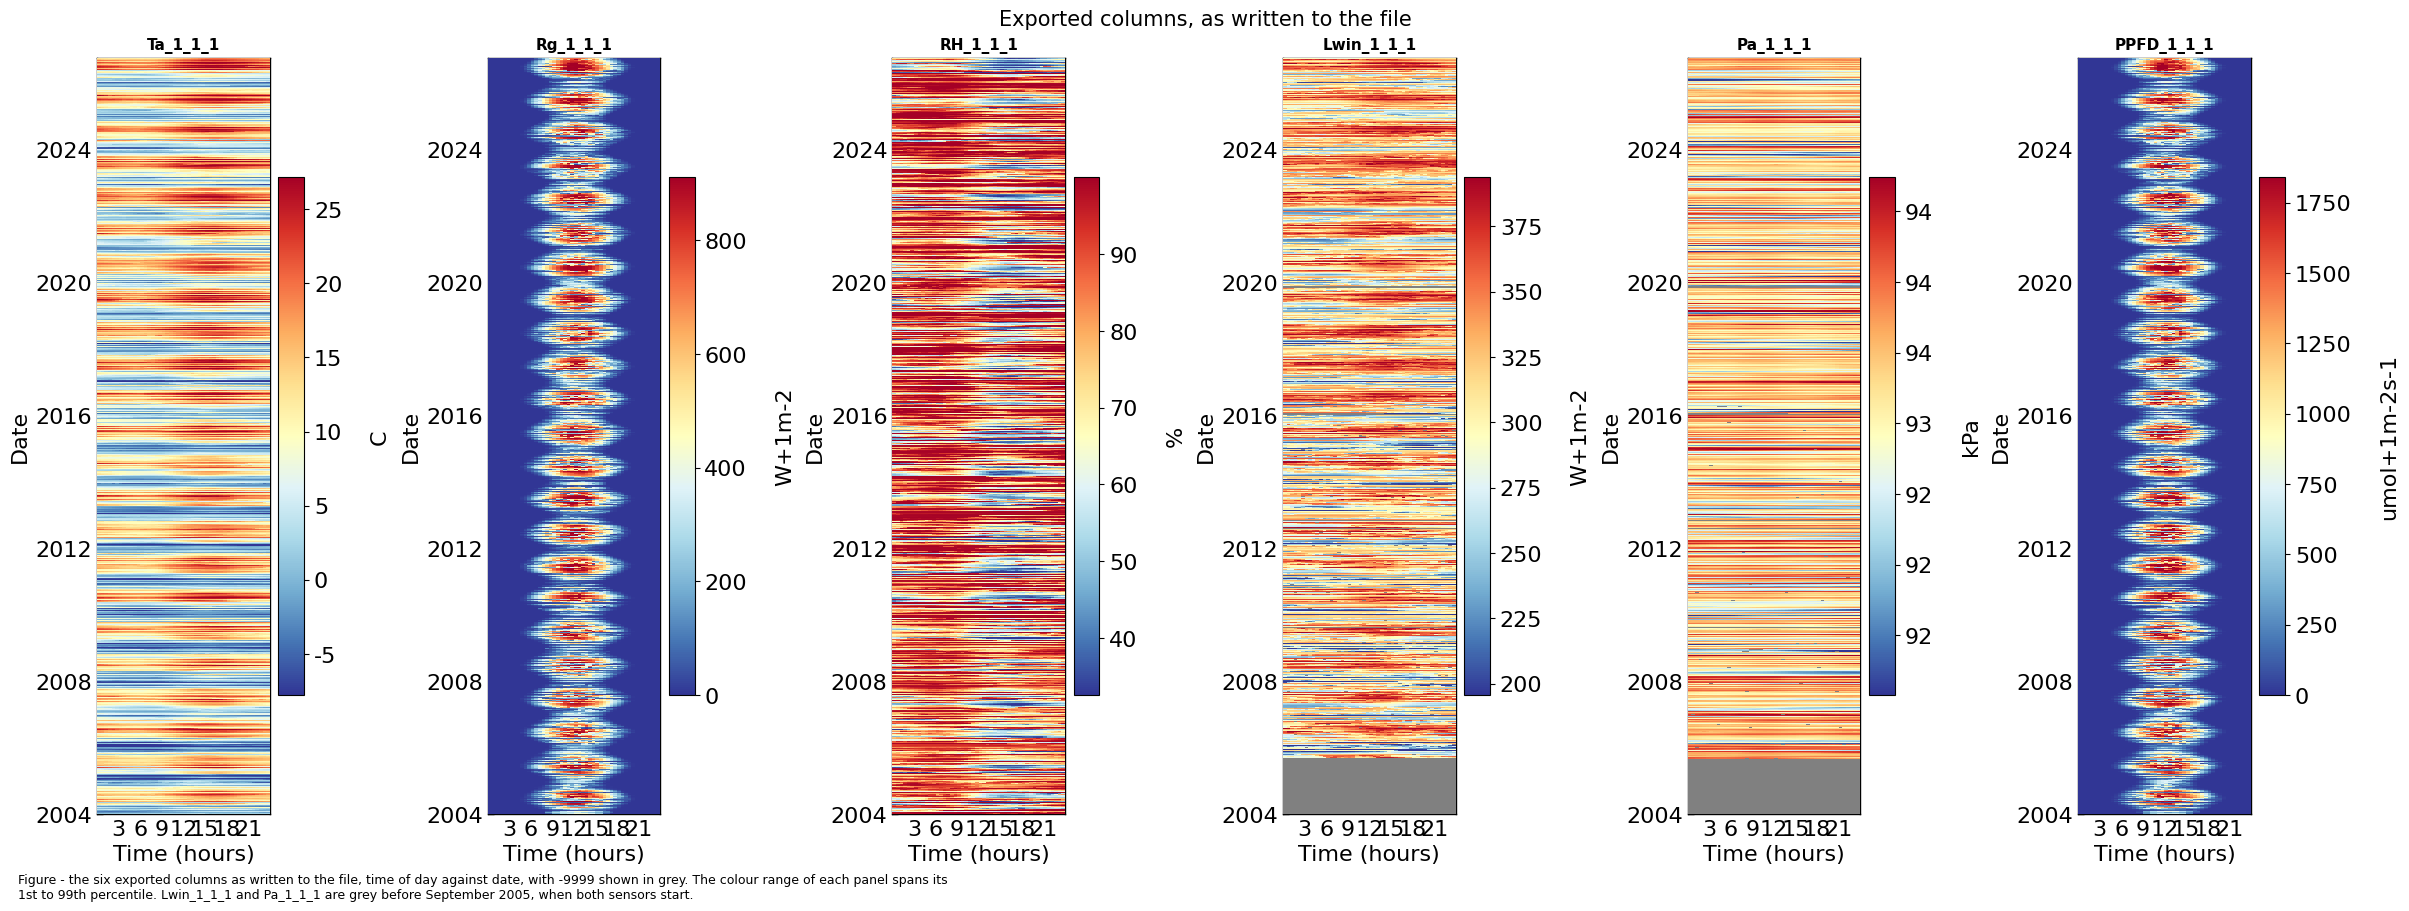

In [10]:
_plotcols = [c for c in res.columns if not str(c[0]).startswith('TIMESTAMP')]
fig, axs = plt.subplots(ncols=len(_plotcols), figsize=(4 * len(_plotcols), 9), dpi=100,
                        layout="constrained")
fig.suptitle("Exported columns, as written to the file", fontsize=15)
for _ax, _col in zip(axs, _plotcols):
    _series = res[_col].replace(to_replace=MISSING_VALUE, value=np.nan)
    _series.name = _col[0]  # the column label is a (name, unit) tuple, the plot wants a name
    dv.plotting.HeatmapDateTime(series=_series).plot(
        ax=_ax, cb_digits_after_comma=0, zlabel=_col[1],
        vmin=_series.quantile(.01), vmax=_series.quantile(.99),
        format_style=dv.plotting.FormatStyle(title=_col[0], title_fontsize=11))
figcap(fig, "the six exported columns as written to the file, time of day against date, with -9999 "
            "shown in grey. The colour range of each panel spans its 1st to 99th percentile. "
            "Lwin_1_1_1 and Pa_1_1_1 are grey before September 2005, when both sensors start.")

## 💾 Export

In [11]:
OUTDIR.mkdir(parents=True, exist_ok=True)
outpath = OUTDIR / f"{OUTNAME}.csv"
res.to_csv(outpath, index=False)  # the timestamp lives in the two columns, not in the index
print(f"Wrote {outpath}")
print(f"      {outpath.stat().st_size / 1024 ** 2:.1f} MB")

Wrote F:\Sync\luhk_work\dev-data\datasets-data\dataset_ch-lae_flux_product-data\workflow\10_METEO\40_EXPORTS\EDDYPRO_BIOMET_CH-LAE_2004-2026.09.csv
      41.0 MB


### Read the written file back

Checked against the file on disk rather than against the frame in memory, since the file is what
EddyPro reads.

In [12]:
with open(outpath) as fh:
    for _ in range(3):
        print(fh.readline().rstrip())

back = pd.read_csv(outpath, header=[0, 1])
assert back.shape == res.shape, f"{res.shape} written, {back.shape} read back"
assert list(back.columns) == list(res.columns), "header lines differ"
_numeric = [c for c in res.columns if not str(c[0]).startswith('TIMESTAMP')]
assert np.allclose(back[_numeric].to_numpy(dtype=float), res[_numeric].to_numpy(dtype=float))
assert (back[('TIMESTAMP_1', 'yyyy-mm-dd')] == res[('TIMESTAMP_1', 'yyyy-mm-dd')].values).all()
assert (back[('TIMESTAMP_2', 'HH:MM')] == res[('TIMESTAMP_2', 'HH:MM')].values).all()
_last = pd.Timestamp(back[('TIMESTAMP_1', 'yyyy-mm-dd')].iloc[-1] + ' '
                     + back[('TIMESTAMP_2', 'HH:MM')].iloc[-1])
assert _last == pd.Timestamp(PERIOD_END) + pd.Timedelta('15min'), f"the file ends at {_last}"
print(f"\nRead back: {len(back):,} rows x {back.shape[1]} columns, matches what was written.")

TIMESTAMP_1,TIMESTAMP_2,Ta_1_1_1,Rg_1_1_1,RH_1_1_1,Lwin_1_1_1,Pa_1_1_1,PPFD_1_1_1
yyyy-mm-dd,HH:MM,C,W+1m-2,%,W+1m-2,kPa,umol+1m-2s-1
2004-01-01,00:30,-3.7713514998027486,0.0,97.71896236557714,-9999.0,-9999.0,0.0



Read back: 398,832 rows x 8 columns, matches what was written.


## 🔍 Comparison with the 2025 file

The flux runs up to setup period `2025_1` read `EDDYPRO_BIOMET_CH-LAE_2004-2025.csv`; the `2026_1`
run reads the file written here. Over their common period the two files should differ only where a
product changed on purpose while it was extended to September 2026. This section checks that and
names the change behind every difference.

What the extension changed in the six products, and therefore what may differ:

- **No measured value.** The screened series in the database are the same, so a record that is
  measured in both files must carry the same value. The single exception is the next point.
- **The probe half-hour of 16 May 2025** (`SOURCE` code `5`, `TIMESTAMP_END` 10:00). It was a
  measured record in the 2025 file. `02` and `04` now date the handling of the 47 m probe to that
  half-hour, remove it and model (`TA`) or reconstruct (`RH`) it.
- **Model fills whose training period now reaches into 2026.** `01` fills `SW_IN` from 2019 onwards
  with one model trained on 2019 to the end of the record, and `03` fills `PPFD_IN` with a model
  trained on the whole record. Both were retrained on a longer record, so their fills move by the
  difference between the two models.
- **Model fills whose period was redrawn at a new probe state.** `02`'s period `P3` (the CS215
  without NABEL) ran to the end of 2025 and now ends at the handling of 16 May 2025, so its model
  was trained on a different set of records.
- **Reconstructions whose offset window changed.** `04` reconstructs a gap from MeteoSwiss Lägern
  with an offset per probe state, year and month, fitted within ±2 calendar years. The CS215
  record from 22 October 2024 was state `0` in the 2025 file and is now states `7` and `6`. The
  state-`0` windows of 2023 and 2024 therefore lost those months, and a record from 22 October 2024
  onwards is now reconstructed with an offset fitted within its own state.
- **Nothing in `PA` and `LW_IN`**, which are exported as measured and have no fills.

The 2025 file's last record, `2026-01-01 00:00`, belongs to the common period. The MeteoSwiss
Lägern reference was downloaded again for the extension and agrees with the earlier download over
the common period, except for that final half-hour of 2025, which was incomplete in the earlier
download. No reconstruction or fill uses the reference at that half-hour, so it does not show up
below.

In [13]:
prev = pd.read_csv(PREVIOUSFILE, header=[0, 1])
assert list(prev.columns) == list(res.columns), "the 2025 file has a different header"
prev.index = pd.to_datetime(prev[('TIMESTAMP_1', 'yyyy-mm-dd')] + ' ' + prev[('TIMESTAMP_2', 'HH:MM')])
prev.index.name = 'TIMESTAMP_END'

# Same timestamp convention: the 2025 file must be the first part of this one, label for label.
assert prev.index.equals(res.index[:len(prev)]), "the timestamps of the common period differ"
common = prev.index
print(f"{PREVIOUSFILE.name}: {len(prev):,} records, {common[0]} -> {common[-1]}")
print(f"{OUTNAME}.csv: {len(res):,} records, {res.index[0]} -> {res.index[-1]}")
print(f"Common period: {len(common):,} records; new records: {len(res) - len(common):,}")

# The flags of the merged product on the same end-of-period labels, for the attribution below.
flags = merged[[f for f in PROVENANCE.values() if f] + [SOURCE_FLAG]].copy()
flags.index = flags.index + pd.Timedelta('15min')
flags = flags.reindex(common)
assert flags.notna().all().all(), "a flag is missing on the common period"

_value_cols = [c for c in res.columns if not str(c[0]).startswith('TIMESTAMP')]
_old = prev[_value_cols].replace(MISSING_VALUE, np.nan)
_new = res.loc[common, _value_cols].replace(MISSING_VALUE, np.nan)

# One row per changed record and column: the value in both files, the difference, and the flags.
_rows = []
for _src, _col in RENAME.items():
    _o, _n = _old[_col], _new[_col]
    _gap_changed = _o.isna() != _n.isna()
    assert not _gap_changed.any(), (
        f"{_col[0]}: {int(_gap_changed.sum())} records changed between a value and -9999")
    _changed = (_n - _o).abs() > 1e-9
    _d = pd.DataFrame({'EddyPro': _col[0], 'old': _o[_changed], 'new': _n[_changed]})
    _d['diff'] = _d['new'] - _d['old']
    _d['provenance'] = flags.loc[_changed, PROVENANCE[_src]] if PROVENANCE[_src] else np.nan
    _d['source'] = flags.loc[_changed, SOURCE_FLAG]
    _rows.append(_d)
changes = pd.concat(_rows)
changes['year'] = changes.index.year
print(f"\nChanged values over the common period: {len(changes):,} "
      f"in {changes.index.nunique():,} half-hours")

EDDYPRO_BIOMET_CH-LAE_2004-2025.csv: 385,728 records, 2004-01-01 00:30:00 -> 2026-01-01 00:00:00
EDDYPRO_BIOMET_CH-LAE_2004-2026.09.csv: 398,832 records, 2004-01-01 00:30:00 -> 2026-10-01 00:00:00
Common period: 385,728 records; new records: 13,104

Changed values over the common period: 10,334 in 9,466 half-hours


### 📋 Table: changed values per column

In [14]:
_summary = []
for _src, _col in RENAME.items():
    _c = changes[changes['EddyPro'] == _col[0]]
    _measured = _c['provenance'] == 0 if PROVENANCE[_src] else pd.Series(True, index=_c.index)
    _summary.append({
        'EddyPro': _col[0],
        'compared': int(_old[_col].notna().sum()),
        'changed': len(_c),
        'changed %': round(100 * len(_c) / max(int(_old[_col].notna().sum()), 1), 3),
        'of which modelled or reconstructed now': int((~_measured).sum()),
        'of which probe half-hour (SOURCE 5)': int((_c['source'] == SOURCE_HANDLED).sum()),
        'mean diff': round(_c['diff'].mean(), 4) if len(_c) else 0.0,
        'max |diff|': round(_c['diff'].abs().max(), 4) if len(_c) else 0.0,
    })
tabcap("values that differ between the 2025 file and this one over their common period, per "
       "column: how many records were compared (not -9999 in the 2025 file), how many differ, how "
       "many of those are modelled or reconstructed records in the current products, how many are "
       "the probe half-hour of 16 May 2025, and the mean and largest difference (new minus old) in "
       "the column's unit")
pd.DataFrame(_summary).set_index('EddyPro')

Table - values that differ between the 2025 file and this one over their common period, per column:
how many records were compared (not -9999 in the 2025 file), how many differ, how many of those are
modelled or reconstructed records in the current products, how many are the probe half-hour of 16
May 2025, and the mean and largest difference (new minus old) in the column's unit



,compared,changed,changed %,of which modelled or reconstructed now,of which probe half-hour (SOURCE 5),mean diff,max |diff|
EddyPro,,,,,,,
Ta_1_1_1,385728,868,0.225,868,1,0.0862,2.1836
Rg_1_1_1,385728,398,0.103,398,0,-0.9789,116.4484
RH_1_1_1,385728,98,0.025,98,1,-0.1740,1.1242
Lwin_1_1_1,350969,0,0.000,0,0,0.0000,0.0000
Pa_1_1_1,352438,0,0.000,0,0,0.0000,0.0000
PPFD_1_1_1,385728,8970,2.325,8970,0,-2.9780,636.8291


### 📋 Table: changed values per column, year and provenance code

The same differences split by year and by the provenance code the record carries now, with the
share of that year's records of that code which changed. A share of 100 % says that a whole fill
population moved together, which is what a retrained model or a refitted offset produces; a few
changed records inside an otherwise unchanged population would point at something else.

In [15]:
_tab = []
for _src, _col in RENAME.items():
    _flag = PROVENANCE[_src]
    _c = changes[changes['EddyPro'] == _col[0]]
    if not _flag or _c.empty:
        continue
    for (_y, _p), _g in _c.groupby(['year', 'provenance']):
        _population = int(((flags.index.year == _y) & (flags[_flag] == _p)).sum())
        _tab.append({'EddyPro': _col[0], 'year': _y, 'provenance code': int(_p),
                     'changed': len(_g), 'of records with this code %': round(100 * len(_g) / _population, 1),
                     'mean diff': round(_g['diff'].mean(), 3),
                     'min diff': round(_g['diff'].min(), 3), 'max diff': round(_g['diff'].max(), 3)})
tabcap("changed values per exported column, year and current provenance code (Ta_1_1_1 and "
       "Rg_1_1_1, PPFD_1_1_1: ISFILLED, 1 = model, 2 = fallback model; RH_1_1_1: MISSING, "
       "4 = reconstructed from Lägern), with the share of that year's records carrying that code "
       "which changed, and the range of the difference new minus old")
pd.DataFrame(_tab).set_index(['EddyPro', 'year', 'provenance code'])

Table - changed values per exported column, year and current provenance code (Ta_1_1_1 and Rg_1_1_1,
PPFD_1_1_1: ISFILLED, 1 = model, 2 = fallback model; RH_1_1_1: MISSING, 4 = reconstructed from
Lägern), with the share of that year's records carrying that code which changed, and the range of
the difference new minus old



changed  of records with this code %  mean diff  min diff  max diff
EddyPro    year provenance code                                                                     
Ta_1_1_1   2019 1                    759                        100.0      0.112    -1.526     2.184
           2023 1                      5                        100.0     -0.037    -0.785     0.414
           2024 1                    103                        100.0     -0.104    -1.003     0.761
           2025 1                      1                        100.0      0.670     0.670     0.670
Rg_1_1_1   2019 1                    310                         99.4      0.422   -88.921    64.910
           2021 1                      6                        100.0    -26.390   -46.685    -1.322
           2023 1                      9                        100.0      1.585    -8.109    16.627
           2024 1                     73                        100.0     -5.155  -116.448    81.089
RH_1_1_1   2023 4                      9                        100.0     -0.108    -0.149     0.181
           2024 4                     88                         82.2     -0.195    -0.220     0.936
           2025 4                      1                        100.0      1.124     1.124     1.124
PPFD_1_1_1 2004 1                   6515                        100.0     -2.051  -636.829   426.962
                2                    570                         99.8    -14.376  -281.745   412.410
           2005 1                     10                        100.0    -26.081  -110.882    42.732
           2006 1                      5                        100.0     13.195    -0.992    47.147
           2008 1                      4                        100.0    -20.374   -27.282   -11.088
           2009 1                    292                        100.0     -1.342   -52.401    50.023
           2010 1                    109                        100.0      7.409   -35.490    58.454
           2011 1                     10                        100.0      3.157   -66.978   106.720
           2012 1                    627                        100.0     -3.127  -204.700   141.801
                2                     29                        100.0    -89.634  -249.918    35.290
           2013 1                     35                        100.0     -0.120   -35.801    32.178
           2016 1                    378                        100.0     -1.464   -64.839    54.247
           2019 1                    312                        100.0     -0.340  -215.176   135.198
           2023 1                      5                        100.0     31.769    -6.928    60.019
           2024 1                     69                        100.0     -3.824  -190.015   224.018

### 📊 Plot: changed values over time

Each changed value as the difference new minus old against its date, one panel per column that
has any. The clusters line up with the populations of the table above.

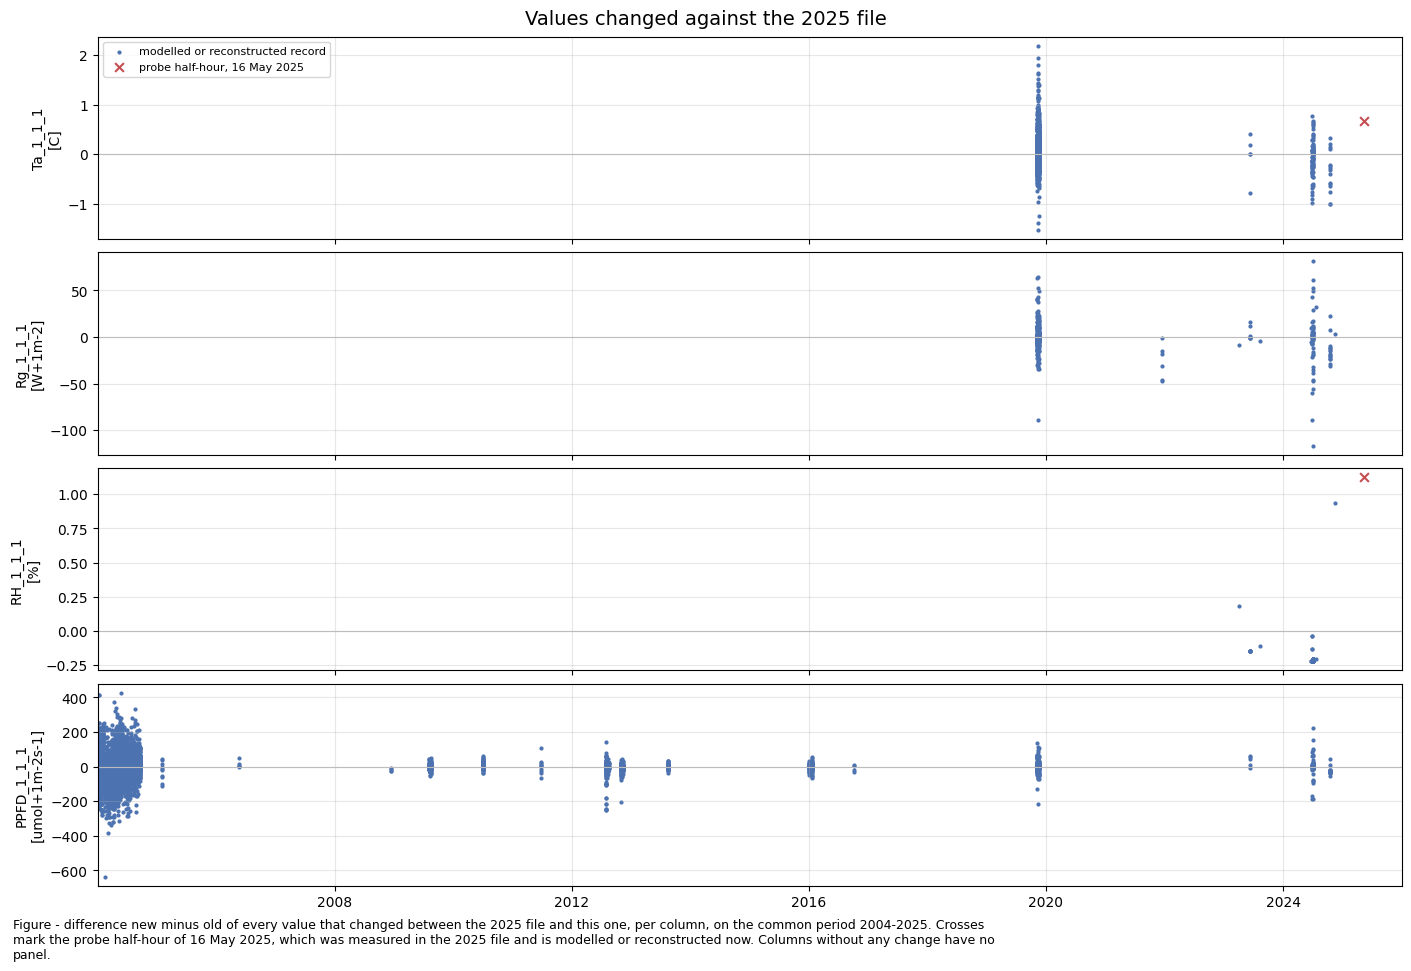

In [16]:
_cols = [c for c in changes['EddyPro'].unique()]
fig, axs = plt.subplots(nrows=len(_cols), figsize=(14, 2.4 * len(_cols)), dpi=100,
                        layout='constrained', sharex=True, squeeze=False)
fig.suptitle('Values changed against the 2025 file', fontsize=14)
_units = {v[0]: v[1] for v in RENAME.values()}
for _ax, _name in zip(axs[:, 0], _cols):
    _c = changes[changes['EddyPro'] == _name]
    _probe = _c['source'] == SOURCE_HANDLED
    _ax.scatter(_c.index[~_probe], _c.loc[~_probe, 'diff'], s=4, color='#4C72B0',
                label='modelled or reconstructed record')
    _ax.scatter(_c.index[_probe], _c.loc[_probe, 'diff'], s=40, marker='x', color='#C44E52',
                label='probe half-hour, 16 May 2025')
    _ax.axhline(0, color='#BDBDBD', lw=0.8)
    _ax.set_ylabel(f"{_name}\n[{_units[_name]}]")
    _ax.grid(alpha=0.3)
axs[0, 0].legend(fontsize=8, loc='upper left')
axs[-1, 0].set_xlim(common[0], common[-1])
figcap(fig, "difference new minus old of every value that changed between the 2025 file and this "
            "one, per column, on the common period 2004-2025. Crosses mark the probe half-hour of "
            "16 May 2025, which was measured in the 2025 file and is modelled or reconstructed now. "
            "Columns without any change have no panel.")

### Attribution

Each population listed at the top of this section is asserted here, so that a difference outside
them stops the notebook instead of passing into the flux runs. The checks are one-sided where a
population is expected to change only in part: a retrained model can reproduce a fill to the last
digit, so a fill that kept its value is allowed, a measured value that changed is not.

In [17]:
_by = {name: changes[changes['EddyPro'] == name] for name in changes['EddyPro'].unique()}
_empty = changes.iloc[0:0]
_ta, _rg = _by.get('Ta_1_1_1', _empty), _by.get('Rg_1_1_1', _empty)
_rh, _ppfd = _by.get('RH_1_1_1', _empty), _by.get('PPFD_1_1_1', _empty)

# 1. PA and LW_IN are exported as measured and did not change.
for _name in ('Pa_1_1_1', 'Lwin_1_1_1'):
    assert _name not in _by, f"{_name}: {len(_by[_name])} values changed in a column with no fills"

# 2. No measured record changed, except the probe half-hour.
_measured_changed = changes[(changes['provenance'] == 0) & (changes['source'] != SOURCE_HANDLED)]
assert _measured_changed.empty, (
    f"{len(_measured_changed)} measured values changed:\n{_measured_changed.head(10)}")

# 3. The probe half-hour changed in TA and RH, and it is the only record of its kind.
_handled = flags.index[flags[SOURCE_FLAG] == SOURCE_HANDLED]
assert len(_handled) == 1, f"expected one probe half-hour in the common period, found {list(_handled)}"
for _name, _c in (('Ta_1_1_1', _ta), ('RH_1_1_1', _rh)):
    assert _handled[0] in _c.index, f"{_name}: the probe half-hour {_handled[0]} did not change"

# 4. SW_IN: only model fills (code 1) of 01's 2019-2026 period.
assert (_rg['provenance'] == 1).all() and (_rg.index >= '2019-01-01 00:30').all(), (
    "Rg_1_1_1: a changed value lies outside the model fills of the 2019-2026 period")

# 5. PPFD_IN: only model and fallback-model fills (codes 1 and 2) of 03's whole-record model.
assert _ppfd['provenance'].isin([1, 2]).all(), "PPFD_1_1_1: a changed value is not a model fill"

# 6. TA: besides the probe half-hour, only model fills (code 1) of the CS215 periods after NABEL.
_ta_fill = _ta[_ta['source'] != SOURCE_HANDLED]
assert (_ta_fill['provenance'] == 1).all() and (_ta_fill.index >= '2019-01-01 00:30').all(), (
    "Ta_1_1_1: a changed value lies outside 02's model fills after the NABEL record")

# 7. RH: besides the probe half-hour, only Lägern reconstructions (code 4) of the CS215 (states 0
# and 7) in 2023-2024, the two years whose +/-2-year offset window reached the re-labelled records.
_rh_fill = _rh[_rh['source'] != SOURCE_HANDLED]
assert (_rh_fill['provenance'] == 4).all() and _rh_fill['source'].isin([0, 7]).all(), (
    "RH_1_1_1: a changed value is not a Lägern reconstruction of the CS215 before May 2025")
assert _rh_fill['year'].isin([2023, 2024]).all(), (
    f"RH_1_1_1: reconstructions changed in {sorted(int(_y) for _y in _rh_fill['year'].unique())}, "
    f"outside the years whose offset window reaches the re-labelled records")

print("Every changed value belongs to one of the listed populations:")
print(f"  probe half-hour {_handled[0]} (TIMESTAMP_END): Ta_1_1_1 {_ta.loc[_handled[0], 'diff']:+.3f} C, "
      f"RH_1_1_1 {_rh.loc[_handled[0], 'diff']:+.3f} %")
for _name, _c in (('Rg_1_1_1', _rg), ('PPFD_1_1_1', _ppfd), ('Ta_1_1_1', _ta_fill), ('RH_1_1_1', _rh_fill)):
    print(f"  {_name:<11} {len(_c):>6,} fills, years {sorted(int(_y) for _y in _c['year'].unique())}")

Every changed value belongs to one of the listed populations:
  probe half-hour 2025-05-16 10:00:00 (TIMESTAMP_END): Ta_1_1_1 +0.670 C, RH_1_1_1 +1.124 %
  Rg_1_1_1       398 fills, years [2019, 2021, 2023, 2024]
  PPFD_1_1_1   8,970 fills, years [2004, 2005, 2006, 2008, 2009, 2010, 2011, 2012, 2013, 2016, 2019, 2023, 2024]
  Ta_1_1_1       867 fills, years [2019, 2023, 2024]
  RH_1_1_1        97 fills, years [2023, 2024]


## 📝 Notes for use

- **Timestamps are end-of-period.** The first record is labelled `2004-01-01 00:30` and the last
  `2026-10-01 00:00`; the file covers January 2004 to September 2026.
- **`-9999` is the missing value**, and it occurs in `Pa_1_1_1` and `Lwin_1_1_1` only. Both start
  in September 2005 and keep the gaps of their products; the other four columns are complete.
- **The file carries no provenance.** `Ta_1_1_1`, `Rg_1_1_1` and `PPFD_1_1_1` are gap-filled and
  `RH_1_1_1` is reconstructed, in the proportions reported above. Which half-hour was measured, and
  by which probe, is recorded only in the flag columns of the products in `30_PRODUCTS`.
- **`Ta_1_1_1` and `RH_1_1_1` are the measured series.** From 5 June 2026 they are HygroVUE10
  readings, which the products bring onto the CS215 level only in their homogenised columns.
- **Over 2004-2025 this file differs from the 2025 file** in the model fills and reconstructions
  listed in the comparison section and in one measured half-hour, 16 May 2025 10:00
  (`TIMESTAMP_END`). Flux runs made from the 2025 file are not affected anywhere else.
- **Re-run this notebook after any product it reads is re-exported**, and after `30_PRODUCTS/99` is
  re-run. It has no state of its own: the file is a view of the merged product at the time it was
  written.

***

In [18]:
_runtime = datetime.now() - NOTEBOOK_START
print(f"Finished: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')} (runtime {_runtime})")

Finished: 2026-10-23 13:06:20 (runtime 0:00:11.925653)
